# Peringkat TFP

ditulis: tim PSE Atha Bintang Wahyu M. | PSE UGM

--> 34 provinsi, 2017–2025.
--> Tenaga kerja 2025 menyalin 2024. Koefisien produksi tetap.
--> Peringkat 1 = tertinggi.
--> TFP terukur = residual tanpa batasan CRS.
--> TFP CRS = residual per pekerja, skala hasil konstan.


In [1]:
from pathlib import Path
import json
import re
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from shapely.geometry import Polygon

NAVY, TEAL, RUST, GRAY, CREAM, PAPER = (
    "#0E2440", "#46A694", "#D9042B", "#797F8C", "#F2E6CE", "#FFFFFF",
)
GRID = "#EEF0F3"
B1, B2, B1C = 0.3874222, 0.1928021, 0.434073
C_IL, C_L = 0.046651, 0.419776
SHORT = {
    11: "Aceh", 12: "Sumut", 13: "Sumbar", 14: "Riau", 15: "Jambi",
    16: "Sumsel", 17: "Bengkulu", 18: "Lampung", 19: "Babel", 21: "Kepri",
    31: "Jakarta", 32: "Jabar", 33: "Jateng", 34: "DIY", 35: "Jatim", 36: "Banten",
    51: "Bali", 52: "NTB", 53: "NTT",
    61: "Kalbar", 62: "Kalteng", 63: "Kalsel", 64: "Kaltim", 65: "Kaltara",
    71: "Sulut", 72: "Sulteng", 73: "Sulsel", 74: "Sultra", 75: "Gorontalo", 76: "Sulbar",
    81: "Maluku", 82: "Malut", 91: "Papua Barat", 94: "Papua",
}
PATHS = ["Jakarta", "Sulteng", "Malut", "Jateng", "Kaltara", "Papua"]
CMAP_RANK = LinearSegmentedColormap.from_list("rank", ["#F4EFE4", "#8FA8C4", NAVY])
CMAP_GAP = LinearSegmentedColormap.from_list("gap", [RUST, "#F7F4EF", TEAL])


def find_root():
    here = Path.cwd().resolve()
    for cand in [here, *here.parents]:
        if (cand / "02 Code" / "BKPM" / "2026bkpm.Rproj").exists():
            return cand
    return Path("/Users/athamawardi/Desktop/Research-Projects/RDSI_Kemeninves")


ROOT = find_root()
OUT = ROOT / "01 Data" / "TFP" / "output" / "revisi_53_61"
OUT.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({
    "figure.facecolor": PAPER, "axes.facecolor": PAPER, "savefig.facecolor": PAPER,
    "font.family": "sans-serif", "font.sans-serif": ["Helvetica Neue", "Arial", "DejaVu Sans"],
    "axes.unicode_minus": False, "axes.titlecolor": NAVY, "text.color": NAVY,
    "axes.labelcolor": NAVY, "xtick.color": GRAY, "ytick.color": NAVY,
    "axes.labelsize": 11, "xtick.labelsize": 10, "ytick.labelsize": 10,
})


def clean(ax, grid="x"):
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["left"].set_color("#E2E5EA")
    ax.spines["bottom"].set_color("#E2E5EA")
    ax.tick_params(length=0)
    if grid:
        ax.set_axisbelow(True)
        ax.grid(True, axis=grid, color=GRID, lw=0.8)


def head(fig, title, subtitle, top=0.88):
    """Store the header; position it after the final subplot layout."""
    fig._report_header = (title, subtitle)
    fig.tight_layout(rect=(0, 0, 1, top))


def _finish_header(fig):
    """Wrap and separate text using rendered sizes, independent of figure height."""
    for artist in getattr(fig, "_report_header_artists", []):
        artist.remove()
    fig._report_header_artists = []
    if not hasattr(fig, "_report_header"):
        return
    fig.canvas.draw()
    renderer = fig.canvas.get_renderer()
    dpi = fig.dpi
    height_px = fig.bbox.height
    width_px = fig.bbox.width * 0.96
    bounds = [ax.get_tightbbox(renderer) for ax in fig.axes if ax.get_visible()]
    bounds += [a.get_window_extent(renderer) for a in fig.legends + fig.texts
               if a.get_visible()]
    content_top = max((b.y1 for b in bounds if b is not None), default=height_px * .9)

    def wrapped(text, size):
        probe = fig.text(0, 0, "", fontsize=size)
        lines = []
        for paragraph in str(text).split("\n"):
            line = ""
            for word in paragraph.split():
                trial = (line + " " + word).strip()
                probe.set_text(trial)
                if line and probe.get_window_extent(renderer).width > width_px:
                    lines.append(line)
                    line = word
                else:
                    line = trial
            lines.append(line)
        probe.remove()
        return "\n".join(lines)

    title, subtitle = fig._report_header
    gap = 10 * dpi / 72
    sub = fig.text(.01, (content_top + gap) / height_px,
                   wrapped(subtitle, 11), ha="left", va="bottom",
                   fontsize=11, color=GRAY, linespacing=1.35)
    fig.canvas.draw()
    sub_box = sub.get_window_extent(fig.canvas.get_renderer())
    main = fig.text(.01, (sub_box.y1 + gap) / height_px,
                    wrapped(title, 16), ha="left", va="bottom",
                    fontsize=16, color=NAVY, fontweight="medium", linespacing=1.25)
    fig._report_header_artists = [main, sub]
    fig.canvas.draw()
    renderer = fig.canvas.get_renderer()
    assert main.get_window_extent(renderer).y0 > sub.get_window_extent(renderer).y1
    assert sub.get_window_extent(renderer).y0 > content_top


def save(fig, name):
    _finish_header(fig)
    fig.savefig(OUT / name, dpi=180, bbox_inches="tight", facecolor=PAPER)
    print(name)
    plt.show()


def rank_desc(s):
    return s.rank(ascending=False, method="min").astype(int)


def ink_for(cmap, val, vmin, vmax):
    t = 0.5 if vmax == vmin else (val - vmin) / (vmax - vmin)
    t = min(1, max(0, t))
    r, g, b, _ = cmap(t)
    lum = 0.299 * r + 0.587 * g + 0.114 * b
    return "white" if lum < 0.62 else NAVY


In [2]:
tfp = pd.read_excel(ROOT / "01 Data/TFP/output/konstruksi/TFP Provinsi 2017-2025.xlsx", sheet_name="tfp")
tfp["Pre_Prov"] = tfp.Pre_Prov.replace({"DI yogyakarta": "DI Yogyakarta"})
tfp["short"] = tfp.Code_Prov.map(SHORT)
u_hat = tfp.log_Y - B1 * tfp.log_K - B2 * tfp.log_L
c_hat = (tfp.log_Y - tfp.log_L) - B1C * (tfp.log_K - tfp.log_L)
assert np.nanmax(np.abs(u_hat - tfp.logtfp_it)) < 1e-5
assert np.nanmax(np.abs(c_hat - tfp.logtfp_it_crs)) < 1e-5
tfp["term_il"] = C_IL * (tfp.log_K - tfp.log_L)
tfp["term_l"] = C_L * tfp.log_L

ann = tfp.copy()
ann["r_u"] = ann.groupby("Year").logtfp_it.transform(rank_desc)
ann["r_c"] = ann.groupby("Year").logtfp_it_crs.transform(rank_desc)
ann["g"] = ann.r_u - ann.r_c
mean = tfp.groupby(["Code_Prov", "Pre_Prov", "short"], as_index=False)[
    ["logtfp_it", "logtfp_it_crs", "log_Y", "term_il", "term_l"]
].mean()
mean["r_u"] = rank_desc(mean.logtfp_it)
mean["r_c"] = rank_desc(mean.logtfp_it_crs)
mean["g"] = mean.r_u - mean.r_c
hist = tfp.loc[tfp.Year <= 2024].groupby(["Code_Prov", "Pre_Prov"], as_index=False)[
    ["logtfp_it", "logtfp_it_crs"]
].mean()
hist["r_u"] = rank_desc(hist.logtfp_it)
hist["r_c"] = rank_desc(hist.logtfp_it_crs)
assert abs(hist.r_u.corr(hist.r_c, method="spearman") - 0.671) < 0.01


## Teks utama


### Gambar 5. Peringkat rata-rata


05_dumbbell_peringkat.png


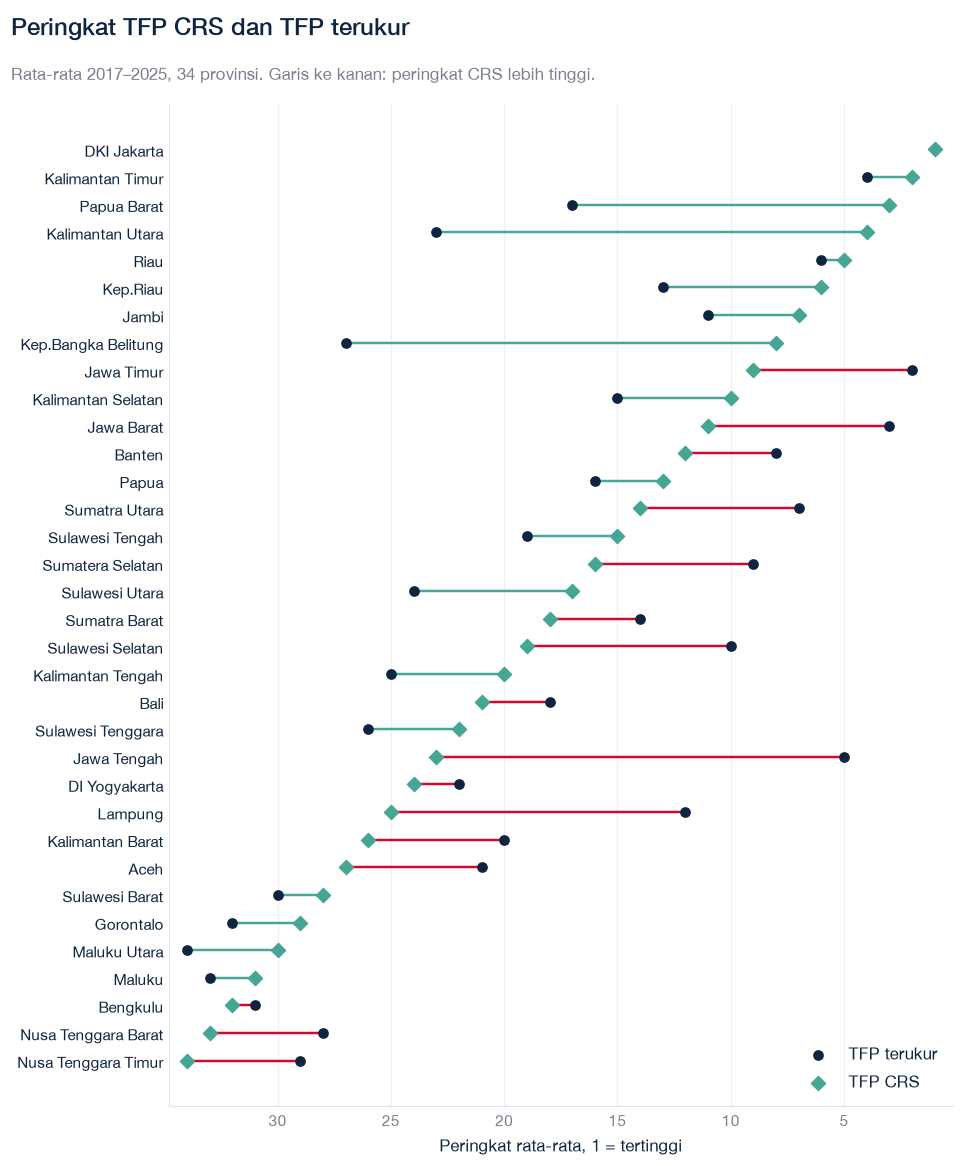

In [3]:
plot = mean.sort_values("r_c").reset_index(drop=True)
y = np.arange(len(plot))
fig, ax = plt.subplots(figsize=(8.8, 11.2))
for i, r in plot.iterrows():
    color = TEAL if r.g > 0 else (RUST if r.g < 0 else "#D5D8DE")
    ax.plot([r.r_u, r.r_c], [i, i], color=color, lw=1.6, zorder=1)
ax.scatter(plot.r_u, y, s=36, color=NAVY, zorder=2, label="TFP terukur")
ax.scatter(plot.r_c, y, s=42, marker="D", color=TEAL, zorder=3, label="TFP CRS")
ax.set_yticks(y)
ax.set_yticklabels(plot.Pre_Prov, fontsize=10)
ax.set_xlabel("Peringkat rata-rata, 1 = tertinggi")
ax.set_xlim(34.8, 0.2)
ax.invert_yaxis()
clean(ax, grid="x")
ax.legend(frameon=False, fontsize=11, loc="lower right")
head(fig, "Peringkat TFP CRS dan TFP terukur",
     "Rata-rata 2017–2025, 34 provinsi. Garis ke kanan: peringkat CRS lebih tinggi.")
save(fig, "05_dumbbell_peringkat.png")


--> Peringkat 1 adalah TFP tertinggi.
--> Garis menghubungkan peringkat rata-rata kedua ukuran pada provinsi yang sama.
--> Urutan baris mengikuti peringkat TFP CRS.


### Gambar 6. Jalur enam provinsi


06_jalur_peringkat.png


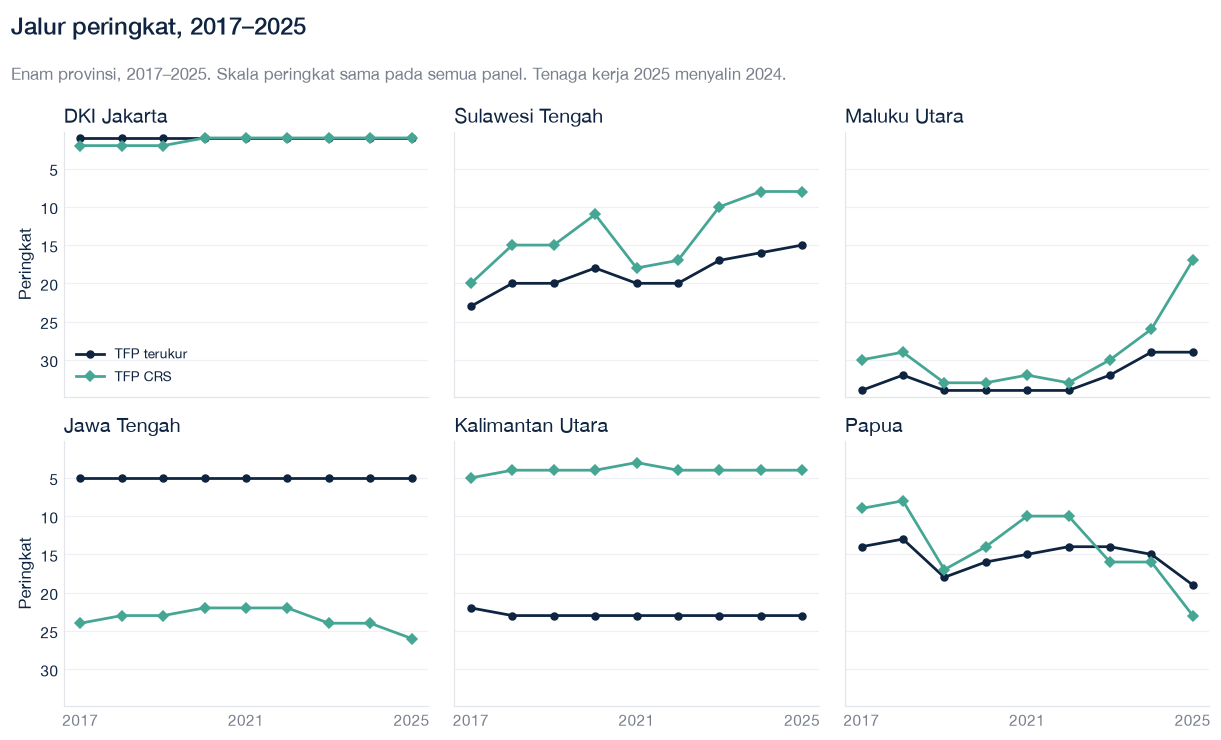

In [4]:
fig, axes = plt.subplots(2, 3, figsize=(11.2, 6.8), sharex=True, sharey=True)
for ax, name in zip(axes.ravel(), PATHS):
    sub = ann.loc[ann.short == name].sort_values("Year")
    ax.plot(sub.Year, sub.r_u, color=NAVY, marker="o", ms=4.5, lw=1.8, label="TFP terukur")
    ax.plot(sub.Year, sub.r_c, color=TEAL, marker="D", ms=4.5, lw=1.8, label="TFP CRS")
    ax.set_ylim(34.8, 0.2)
    ax.set_title(sub.Pre_Prov.iloc[0], loc="left", fontsize=13)
    clean(ax, grid="y")
    ax.set_xticks([2017, 2021, 2025])
axes[0, 0].legend(frameon=False, fontsize=9, loc="lower left")
axes[0, 0].set_ylabel("Peringkat")
axes[1, 0].set_ylabel("Peringkat")
head(fig, "Jalur peringkat, 2017–2025",
     "Enam provinsi, 2017–2025. Skala peringkat sama pada semua panel. Tenaga kerja 2025 menyalin 2024.")
save(fig, "06_jalur_peringkat.png")


--> Peringkat dihitung ulang setiap tahun dengan koefisien yang sama.


### Gambar 7. Peringkat 2017 dan 2025


07_peringkat_2017_2025.png


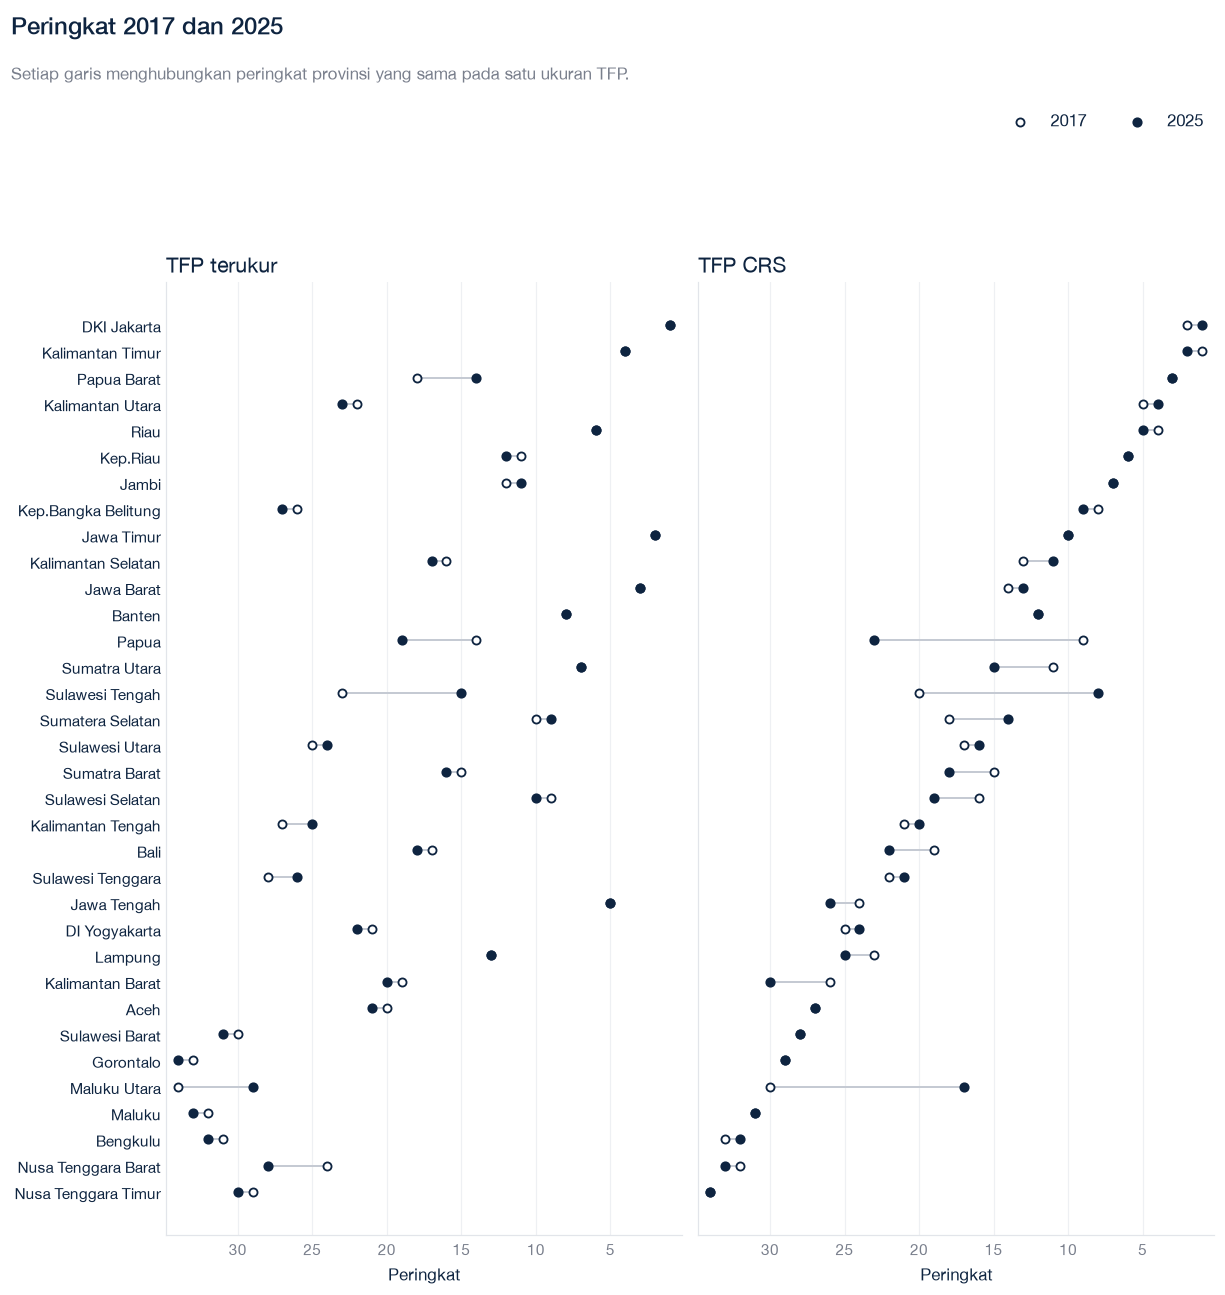

In [5]:
order = mean.sort_values("r_c").short.tolist()
names = mean.set_index("short").Pre_Prov
fig, axes = plt.subplots(1, 2, figsize=(11.2, 11.0), sharey=True)
for ax, col, title in zip(axes, ["r_u", "r_c"], ["TFP terukur", "TFP CRS"]):
    wide = ann.pivot(index="short", columns="Year", values=col).loc[order]
    yy = np.arange(len(wide))
    for i, (idx, r) in enumerate(wide.iterrows()):
        ax.plot([r[2017], r[2025]], [i, i], color="#C5CAD3", lw=1.3, zorder=1)
    ax.scatter(wide[2017], yy, s=28, facecolor=PAPER, edgecolor=NAVY, linewidth=1.2, zorder=2, label="2017")
    ax.scatter(wide[2025], yy, s=32, color=NAVY, zorder=3, label="2025")
    ax.set_xlim(34.8, 0.2)
    ax.set_title(title, loc="left", fontsize=14)
    ax.set_xlabel("Peringkat")
    clean(ax, grid="x")
axes[0].invert_yaxis()
axes[0].set_yticks(np.arange(len(order)))
axes[0].set_yticklabels(names.loc[order], fontsize=10)
handles, labels = axes[0].get_legend_handles_labels()
head(fig, "Peringkat 2017 dan 2025",
     "Setiap garis menghubungkan peringkat provinsi yang sama pada satu ukuran TFP.")
fig.legend(handles, labels, loc="lower right", bbox_to_anchor=(0.99, 0.955),
           ncol=2, frameon=False, fontsize=11)
save(fig, "07_peringkat_2017_2025.png")


--> Lingkaran kosong adalah 2017 dan titik penuh adalah 2025.
--> Tenaga kerja 2025 menyalin 2024.
--> Urutan baris sama dengan gambar peringkat rata-rata.
--> Dua tahun di dalam satu ukuran TFP.


## Lampiran


A2_selisih_peringkat.png
A5_aritmetika.png
A6_matriks_peringkat.png
A7_matriks_perubahan.png
A4_spearman.png
A3_peta_selisih.png


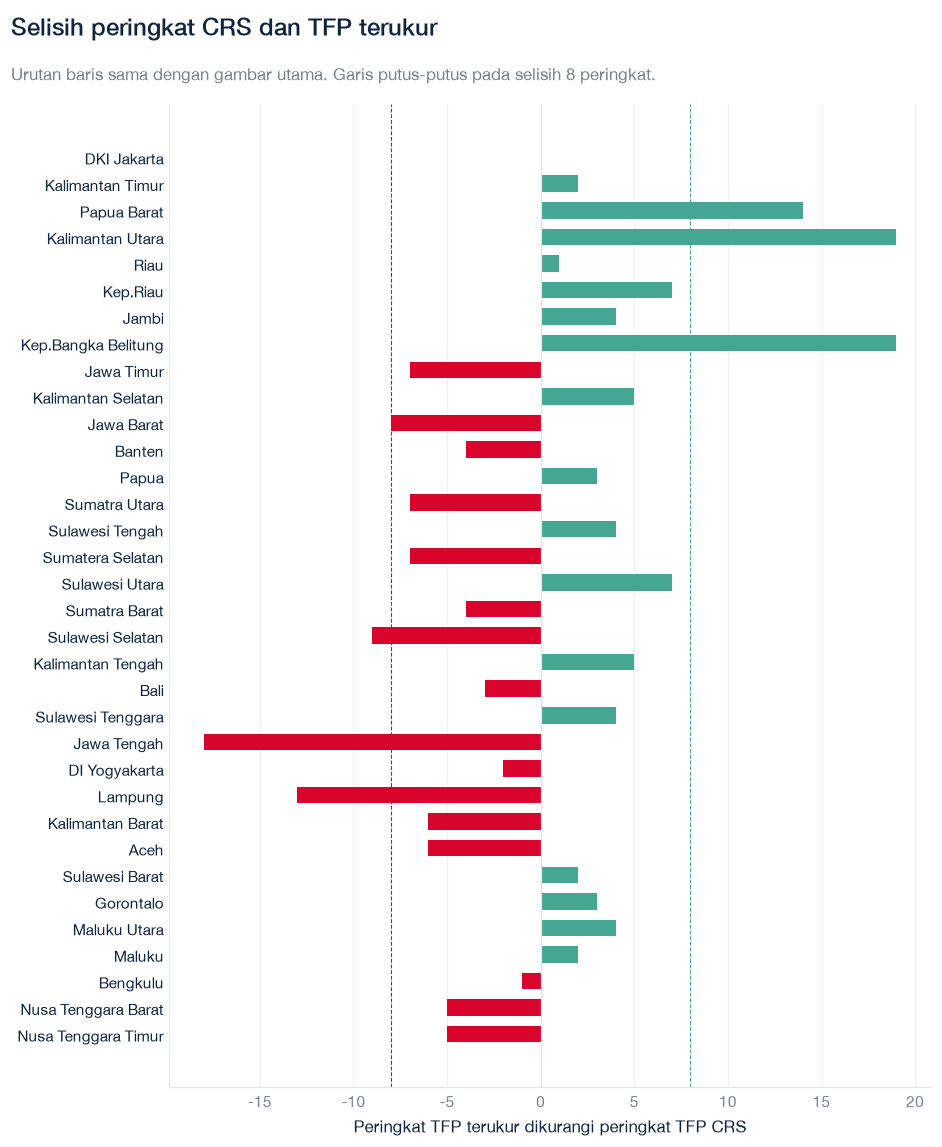

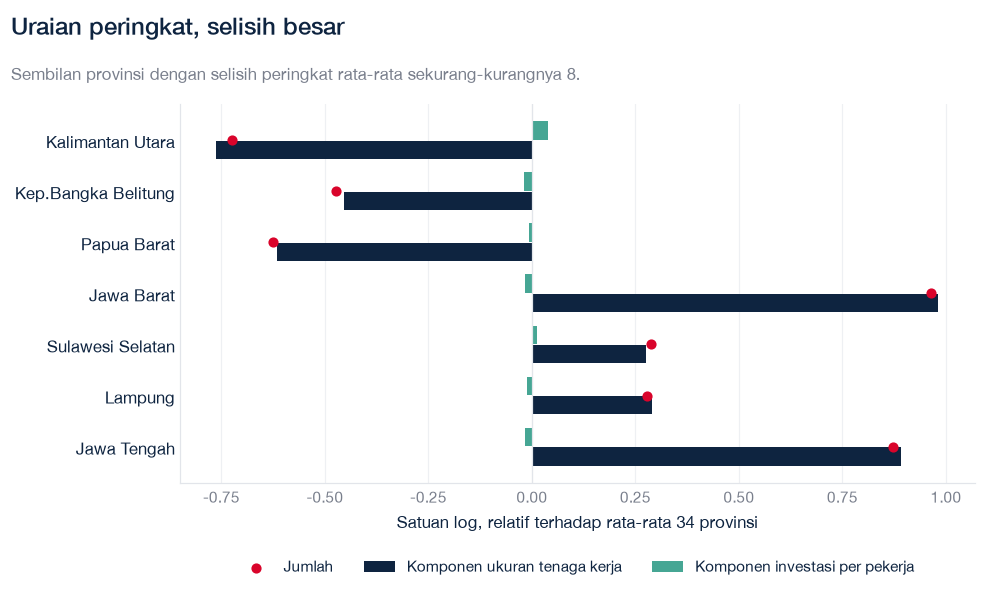

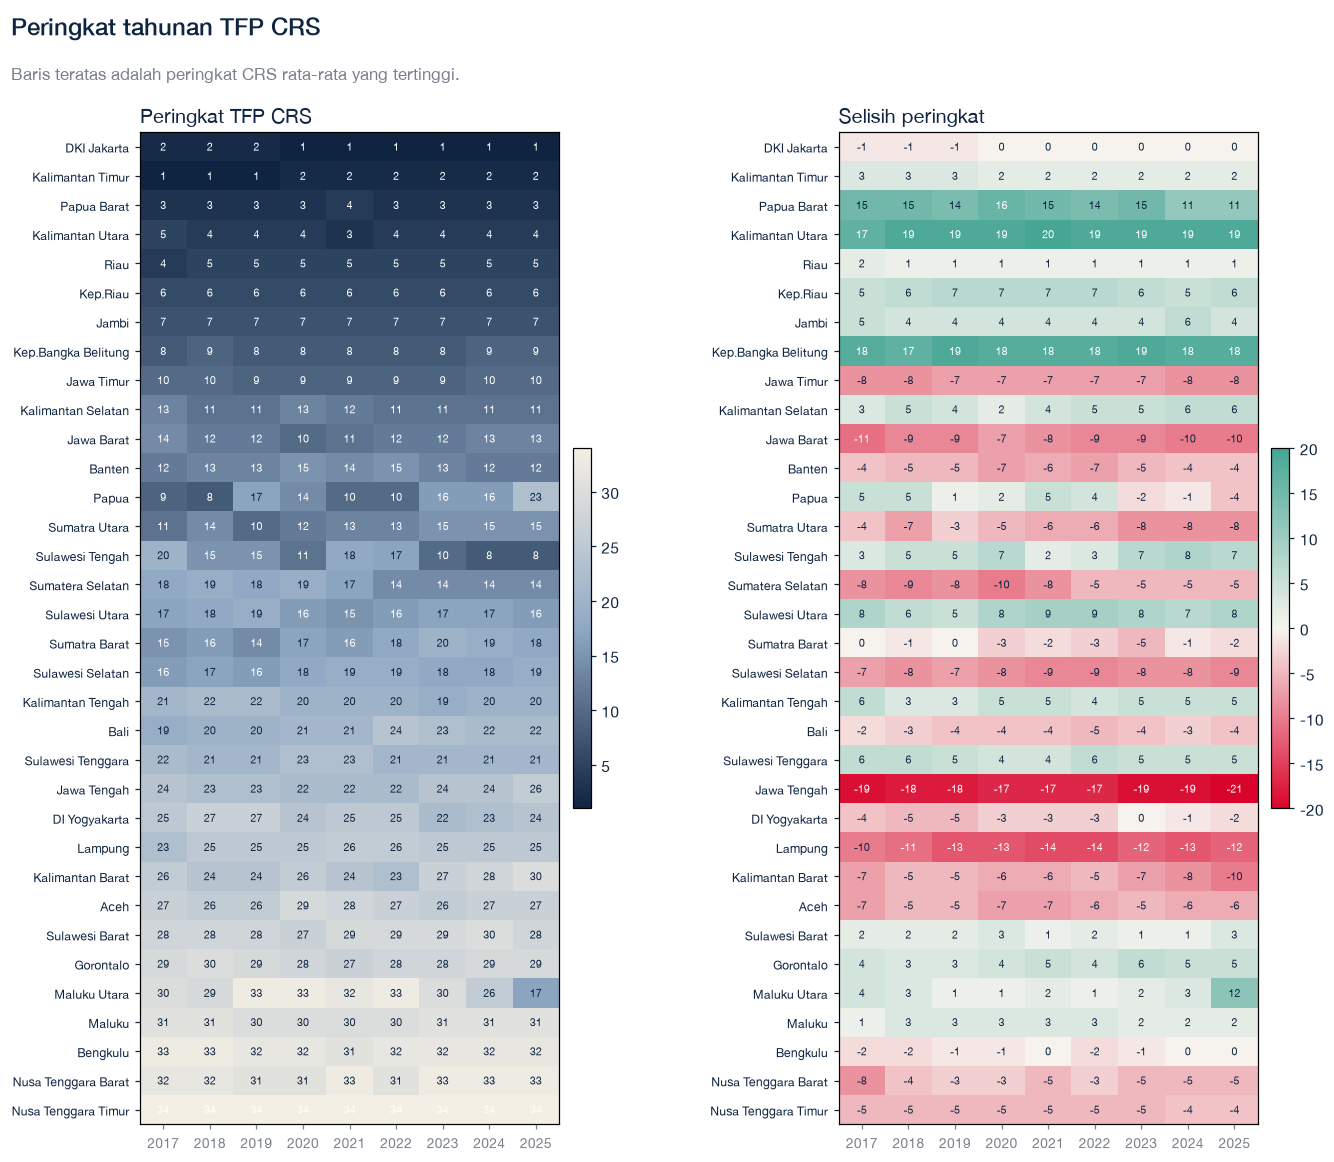

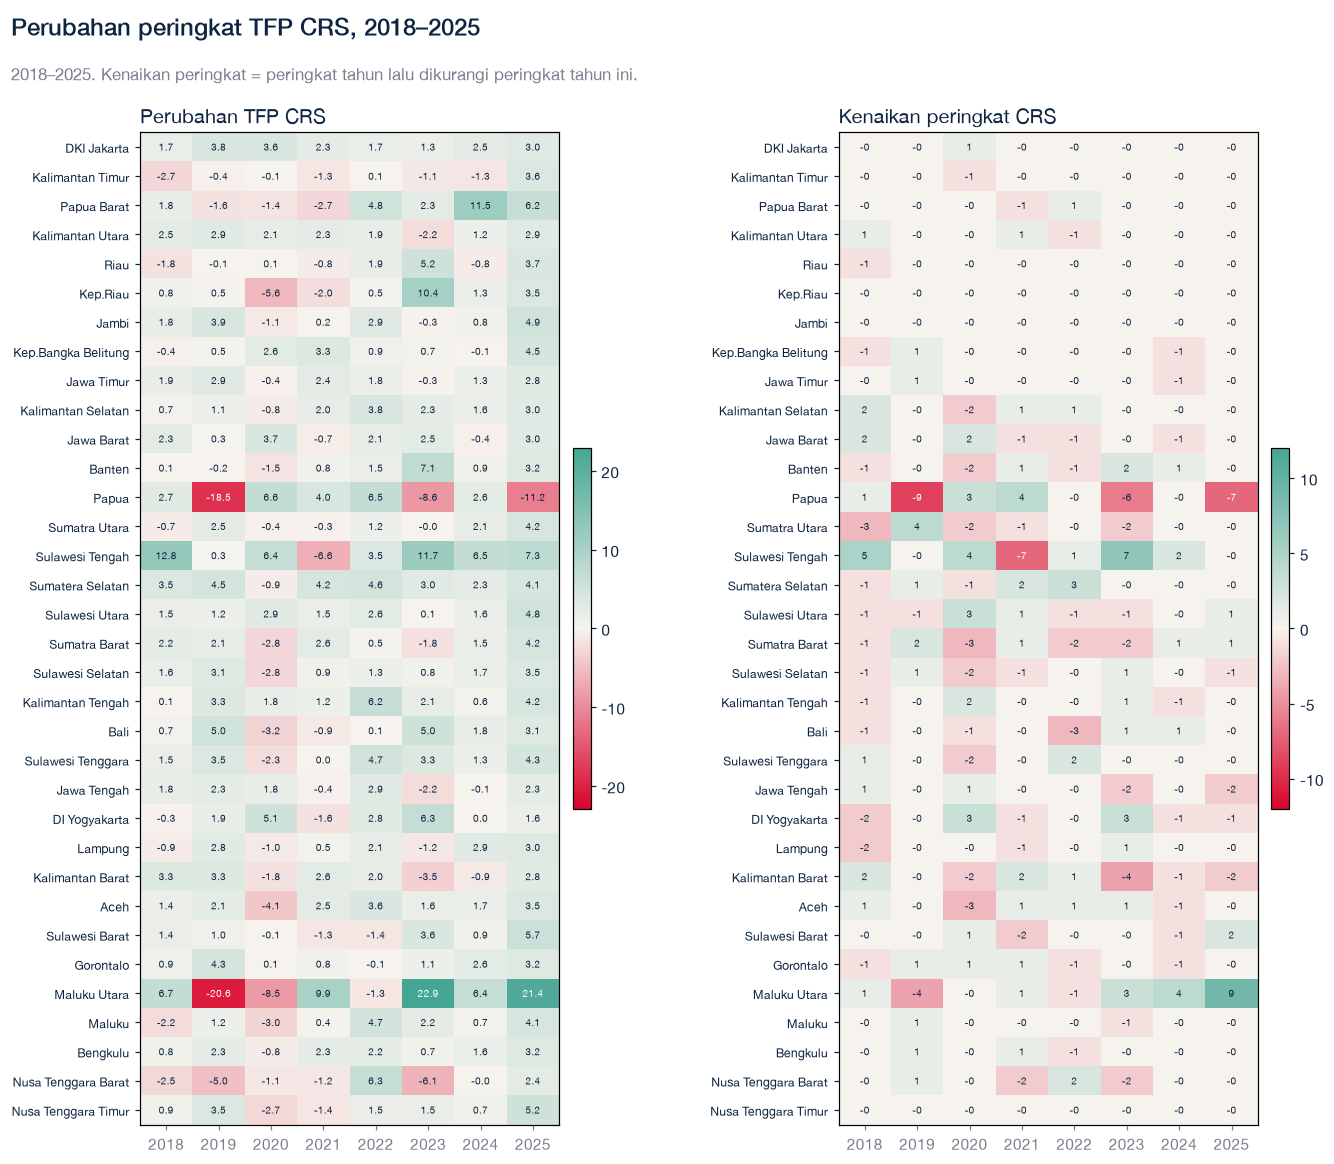

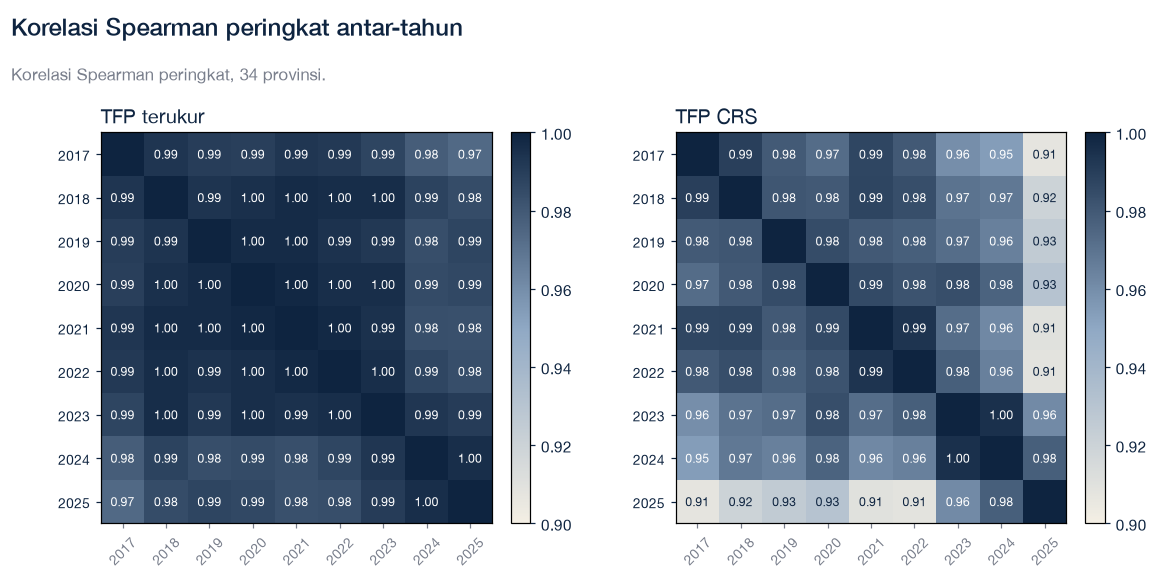

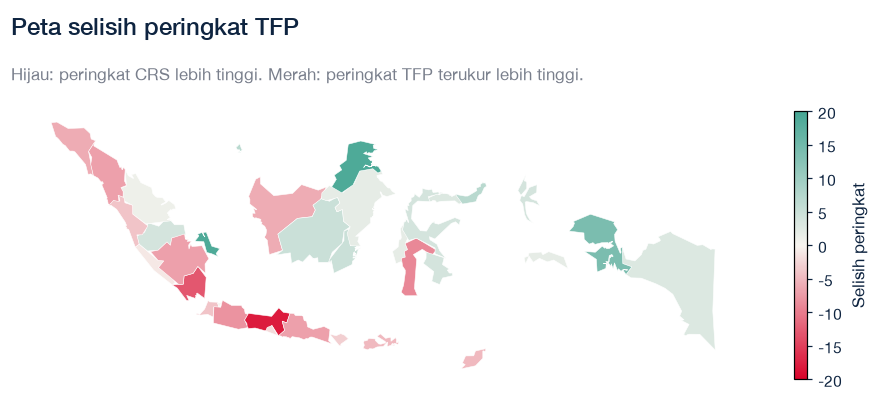

In [6]:
fig, ax = plt.subplots(figsize=(8.6, 11.0))
colors = [TEAL if g_ > 0 else (RUST if g_ < 0 else "#D5D8DE") for g_ in plot.g]
ax.barh(y, plot.g, color=colors, height=0.62)
ax.axvline(0, color="#E2E5EA", lw=0.8)
ax.axvline(8, color=TEAL, lw=0.7, ls="--")
ax.axvline(-8, color=RUST, lw=0.7, ls="--")
ax.set_yticks(y)
ax.set_yticklabels(plot.Pre_Prov, fontsize=10)
ax.set_xlabel("Peringkat TFP terukur dikurangi peringkat TFP CRS")
ax.invert_yaxis()
clean(ax, grid="x")
head(fig, "Selisih peringkat CRS dan TFP terukur",
     "Urutan baris sama dengan gambar utama. Garis putus-putus pada selisih 8 peringkat.")
save(fig, "A2_selisih_peringkat.png")

long = mean.loc[mean.g.abs() >= 8].copy()
long["il_c"] = long.term_il - mean.term_il.mean()
long["l_c"] = long.term_l - mean.term_l.mean()
long = long.sort_values("g")
fig, ax = plt.subplots(figsize=(9.0, 5.4))
yy = np.arange(len(long))
ax.barh(yy, long.l_c, color=NAVY, height=0.36, label="Komponen ukuran tenaga kerja")
ax.barh(yy + 0.38, long.il_c, color=TEAL, height=0.36, label="Komponen investasi per pekerja")
ax.scatter(long.l_c + long.il_c, yy + 0.19, color=RUST, s=32, zorder=3, label="Jumlah")
ax.axvline(0, color="#E2E5EA", lw=0.8)
ax.set_yticks(yy + 0.19)
ax.set_yticklabels(long.Pre_Prov, fontsize=11)
ax.set_xlabel("Satuan log, relatif terhadap rata-rata 34 provinsi")
clean(ax, grid="x")
ax.legend(frameon=False, fontsize=10, loc="upper center", bbox_to_anchor=(0.5, -0.16), ncol=3)
head(fig, "Uraian peringkat, selisih besar",
     "Sembilan provinsi dengan selisih peringkat rata-rata sekurang-kurangnya 8.")
save(fig, "A5_aritmetika.png")

order_s = mean.sort_values("r_c").short.tolist()
labels = mean.sort_values("r_c").Pre_Prov.tolist()
heat_c = ann.pivot(index="short", columns="Year", values="r_c").loc[order_s]
heat_g = ann.pivot(index="short", columns="Year", values="g").loc[order_s]
fig, axes = plt.subplots(1, 2, figsize=(12.2, 11.0))
mats = [
    (axes[0], heat_c, "Peringkat TFP CRS", CMAP_RANK.reversed(), 1, 34, True),
    (axes[1], heat_g, "Selisih peringkat", CMAP_GAP, -20, 20, False),
]
for ax, mat, title, cmap, vmin, vmax, is_rank in mats:
    arr = mat.to_numpy()
    im = ax.imshow(arr, cmap=cmap, vmin=vmin, vmax=vmax, aspect="auto")
    ax.set_xticks(range(arr.shape[1]))
    ax.set_xticklabels(mat.columns.astype(int), fontsize=9)
    ax.set_yticks(range(len(labels)))
    ax.set_yticklabels(labels, fontsize=8)
    ax.set_title(title, loc="left", fontsize=13)
    for i in range(arr.shape[0]):
        for j in range(arr.shape[1]):
            val = arr[i, j]
            ax.text(j, i, f"{int(val)}", ha="center", va="center", fontsize=7,
                    color=ink_for(cmap, val, vmin, vmax))
    fig.colorbar(im, ax=ax, fraction=0.04, pad=0.03)
head(fig, "Peringkat tahunan TFP CRS",
     "Baris teratas adalah peringkat CRS rata-rata yang tertinggi.", top=0.90)
fig.subplots_adjust(wspace=0.55, top=0.88, bottom=0.06)
save(fig, "A6_matriks_peringkat.png")

chg = ann.sort_values(["Code_Prov", "Year"]).copy()
chg["d_c"] = 100 * chg.groupby("Code_Prov").logtfp_it_crs.diff()
chg["gain"] = -chg.groupby("Code_Prov").r_c.diff()
chg = chg.dropna(subset=["d_c"])
mat_d = chg.pivot(index="short", columns="Year", values="d_c").loc[order_s]
mat_g = chg.pivot(index="short", columns="Year", values="gain").loc[order_s]
lim = np.nanmax(np.abs(mat_d.to_numpy()))
fig, axes = plt.subplots(1, 2, figsize=(12.2, 11.0))
for ax, mat, title, vmin, vmax, fmt in [
    (axes[0], mat_d, "Perubahan TFP CRS", -lim, lim, "{:.1f}"),
    (axes[1], mat_g, "Kenaikan peringkat CRS", -12, 12, "{:.0f}"),
]:
    arr = mat.to_numpy()
    im = ax.imshow(arr, cmap=CMAP_GAP, vmin=vmin, vmax=vmax, aspect="auto")
    ax.set_xticks(range(mat.shape[1]))
    ax.set_xticklabels(mat.columns.astype(int), fontsize=10)
    ax.set_yticks(range(len(labels)))
    ax.set_yticklabels(labels, fontsize=8)
    ax.set_title(title, loc="left", fontsize=13)
    for i in range(arr.shape[0]):
        for j in range(arr.shape[1]):
            val = arr[i, j]
            ax.text(j, i, fmt.format(val), ha="center", va="center", fontsize=6.5,
                    color=ink_for(CMAP_GAP, val, vmin, vmax))
    fig.colorbar(im, ax=ax, fraction=0.04, pad=0.03)
head(fig, "Perubahan peringkat TFP CRS, 2018–2025",
     "2018–2025. Kenaikan peringkat = peringkat tahun lalu dikurangi peringkat tahun ini.", top=0.90)
fig.subplots_adjust(wspace=0.55, top=0.88, bottom=0.06)
save(fig, "A7_matriks_perubahan.png")

years = list(range(2017, 2026))
fig, axes = plt.subplots(1, 2, figsize=(10.6, 4.8))
for ax, col, title in [(axes[0], "r_u", "TFP terukur"), (axes[1], "r_c", "TFP CRS")]:
    wide = ann.pivot(index="Code_Prov", columns="Year", values=col)[years]
    corr = wide.corr(method="spearman")
    im = ax.imshow(corr, cmap=CMAP_RANK, vmin=0.9, vmax=1, aspect="equal")
    n = len(years)
    ax.set_xticks(range(n))
    ax.set_yticks(range(n))
    ax.set_xticklabels(years, rotation=45, fontsize=9)
    ax.set_yticklabels(years, fontsize=9)
    ax.set_title(title, loc="left", fontsize=13)
    for i in range(n):
        for j in range(n):
            val = corr.iloc[i, j]
            ax.text(j, i, f"{val:.2f}", ha="center", va="center", fontsize=8,
                    color=ink_for(CMAP_RANK, val, 0.9, 1))
    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
head(fig, "Korelasi Spearman peringkat antar-tahun",
     "Korelasi Spearman peringkat, 34 provinsi.")
save(fig, "A4_spearman.png")

raw = json.loads((ROOT / "01 Data/TFP/output/luaran 2/maps/canvas_polygons.json").read_text())
geoms = []
for rec in raw:
    nums = list(map(float, re.findall(r"[-+]?\d*\.?\d+", rec["d"])))
    coords = list(zip(nums[0::2], [-v for v in nums[1::2]]))
    geoms.append({"Code_Prov": int(rec["c"]), "geometry": Polygon(coords)})
gdf = gpd.GeoDataFrame(geoms, geometry="geometry").merge(mean[["Code_Prov", "g"]], on="Code_Prov")
fig, ax = plt.subplots(figsize=(8.6, 4.6))
gdf.plot(column="g", cmap=CMAP_GAP, vmin=-20, vmax=20, ax=ax, edgecolor="white", linewidth=0.35,
         legend=True, legend_kwds={"label": "Selisih peringkat", "shrink": 0.65})
ax.set_axis_off()
head(fig, "Peta selisih peringkat TFP",
     "Hijau: peringkat CRS lebih tinggi. Merah: peringkat TFP terukur lebih tinggi.")
save(fig, "A3_peta_selisih.png")


--> Lampiran menyimpan selisih peringkat, uraian aritmetikanya, matriks tahunan, korelasi antar-tahun, dan peta sebaran.
